# Protein MD exploration: coordinates vs. contact networks

A molecular dynamics (MD) simulation is a "movie" of a protein moving: thousands of frames, each one a snapshot of where every atom is. Biologists want to know what the protein does during that movie. Does it stay the same, switch between different shapes, or slowly change? Looking at 10,000 frames one by one is impossible, so you need summaries.

Your notebook tries two ways to describe each frame:

by the 3D coordinates of its atoms, and
by its contact network: which parts of the protein touch each other.

For both, you squeeze all frames into a 2D plot so you can see patterns at a glance. When a pattern appears (for example two separate groups of frames), you zoom in to find out what physically changed. That last step, going from "something changes" to "this is what changes," is exactly what the visualization tool for your project is meant to support.

1. Load ATLAS trajectories (CA atoms only).
2. Dimensionality reduction (DR) on the raw coordinates: PCA and t-SNE, coloured by time and RMSD.
3. Build a contact graph (contact map) for single frames.
4. Snapshots-to-Points: turn every frame's contact map into a vector and apply the same DR.
5. Compare the coordinate-based and network-based projections.

In [1]:
import mdtraj as md
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

## Settings

All values you might want to change are here.

- `STRIDE`: keep every n-th frame. ATLAS has 10,001 frames over 100 ns (one per 10 ps), so `STRIDE = 5` gives about 2,000 frames that cover the whole simulation.
- `CONTACT_THRESHOLD`: distance (Å) below which two CA atoms count as "in contact".

In [2]:
proteins = ["16pk_A", "1a62_A", "1ab1_A"]

STRIDE = 5                      # every 5th frame -> ~2000 frames over the full 100 ns
CONTACT_THRESHOLD = 8.0         # Å, used for the network analysis
THRESHOLDS_TO_COMPARE = [4.5, 6.0, 8.0]   # Å, for the threshold comparison plots
RANDOM_STATE = 42               # makes t-SNE reproducible


def file_paths(protein):
    """Return the PDB (topology) and XTC (trajectory) paths for one ATLAS entry."""
    folder = f"{protein}_protein"
    pdb = f"{folder}/{protein}.pdb"
    # Note: the '_fit' trajectory is already aligned by ATLAS
    # (rotation and translation removed), so the RMSD below is effectively aligned RMSD.
    xtc = f"{folder}/{protein}_prod_R1_fit.xtc"
    return pdb, xtc

## 1. Load the trajectories

The PDB file tells MDTraj which atom is which (topology); the XTC file holds the coordinates of every frame.
We keep only the alpha carbons (CA): one atom per residue, so each frame becomes an N × 3 array.

MDTraj stores coordinates in **nanometres**. We convert to **ångströms** (× 10) right away, so every distance in this notebook is in Å.

In [3]:
data = {}

for protein in proteins:
    pdb, xtc = file_paths(protein)

    # stride=STRIDE loads only every STRIDE-th frame (faster and uses less memory)
    traj = md.load(xtc, top=pdb, stride=STRIDE)

    # Keep only the CA atoms
    ca = traj.topology.select("name CA")
    traj_ca = traj.atom_slice(ca)

    coords = traj_ca.xyz * 10          # (M, N, 3), converted from nm to Å
    time_ns = traj_ca.time / 1000      # MDTraj time is in ps

    data[protein] = {
        "traj": traj_ca,
        "coords": coords,
        "time_ns": time_ns,
        "X": coords.reshape(len(coords), -1),   # flattened: (M, 3N)
    }

    M, N, _ = coords.shape
    print(f"{protein}: {M} frames, {N} residues, "
          f"time {time_ns[0]:.0f}-{time_ns[-1]:.0f} ns, flattened shape {data[protein]['X'].shape}")

16pk_A: 2001 frames, 415 residues, time 0-100 ns, flattened shape (2001, 1245)
1a62_A: 2001 frames, 130 residues, time 0-100 ns, flattened shape (2001, 390)
1ab1_A: 2001 frames, 46 residues, time 0-100 ns, flattened shape (2001, 138)


## 2. RMSD to the first frame

RMSD (root mean square deviation) is the average distance between corresponding atoms of two structures:

$$\mathrm{RMSD} = \sqrt{\frac{1}{N}\sum_{i=1}^{N} \lVert x_i - x_i^{\mathrm{ref}} \rVert^2}$$

16pk_A: RMSD range 0.00-3.87 Å
1a62_A: RMSD range 0.00-3.55 Å
1ab1_A: RMSD range 0.00-1.83 Å


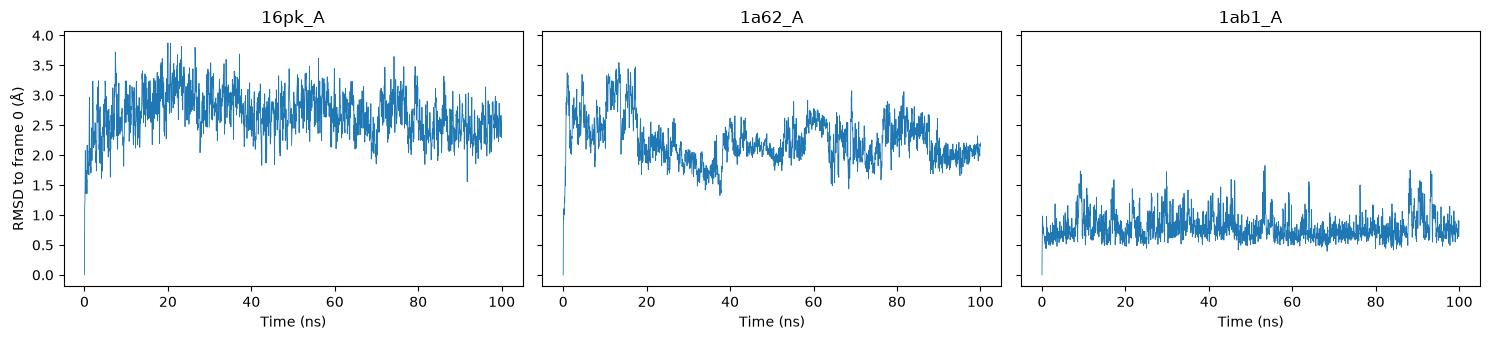

In [4]:
for protein in proteins:
    coords = data[protein]["coords"]
    reference = coords[0]

    # squared distance per atom (sum over x, y, z), mean over atoms, square root
    rmsd = np.sqrt(((coords - reference) ** 2).sum(axis=-1).mean(axis=-1))
    data[protein]["rmsd"] = rmsd

    print(f"{protein}: RMSD range {rmsd.min():.2f}-{rmsd.max():.2f} Å")

fig, axes = plt.subplots(1, len(proteins), figsize=(15, 3.5), sharey=True)
for ax, protein in zip(axes, proteins):
    ax.plot(data[protein]["time_ns"], data[protein]["rmsd"], lw=0.6)
    ax.set_title(protein)
    ax.set_xlabel("Time (ns)")
axes[0].set_ylabel("RMSD to frame 0 (Å)")
plt.tight_layout()
plt.show()

- 16pk_A rises to about 2.5–3 Å in the first few nanoseconds, then fluctuates around that level. The initial rise is the protein relaxing from its crystal structure into simulation conditions, which is normal.
- 1a62_A shows more structure. It jumps to about 3 Å, stays there until about 17 ns, then drops to about 2 Å and alternates between plateaus (higher around 55–65 ns and 80–88 ns). Plateaus with jumps between them hint at the protein switching between a few substates.
- 1ab1_A stays flat around 0.7 Å with brief spikes. It's a small, rigid protein that barely changes, which makes it a useful control case.

RMSD is the standard summary biologists use, but it hides a lot. It says how much a structure changed, not where or how. Two completely different changes can give the same RMSD. That's why the next steps look for richer ways to summarise frames.

## 3. Dimensionality reduction on coordinates

Each frame is a point in 3N-dimensional space (all CA coordinates in one vector).
We project these points to 2D with:

- **PCA**: linear; finds the directions of largest variance. The explained variance ratio tells how much of the total movement the 2D plot captures.
- **t-SNE**: non-linear; tries to keep similar frames close together. Good at showing clusters, but distances between clusters and cluster sizes are not meaningful.

Each projection is coloured twice: by simulation time and by RMSD to the first frame.

In [5]:
for protein in proteins:
    X = data[protein]["X"]

    pca = PCA(n_components=2)
    data[protein]["coord_pca"] = pca.fit_transform(X)
    data[protein]["coord_pca_var"] = pca.explained_variance_ratio_

    # init="pca" gives t-SNE a more stable starting layout than random initialisation
    data[protein]["coord_tsne"] = TSNE(
        n_components=2, perplexity=30, init="pca", random_state=RANDOM_STATE
    ).fit_transform(X)

    v = data[protein]["coord_pca_var"]
    print(f"{protein}: coordinate PCA explained variance PC1 {v[0]:.1%}, PC2 {v[1]:.1%}, total {v.sum():.1%}")

16pk_A: coordinate PCA explained variance PC1 32.8%, PC2 16.0%, total 48.9%
1a62_A: coordinate PCA explained variance PC1 37.6%, PC2 22.5%, total 60.1%
1ab1_A: coordinate PCA explained variance PC1 31.7%, PC2 11.9%, total 43.6%


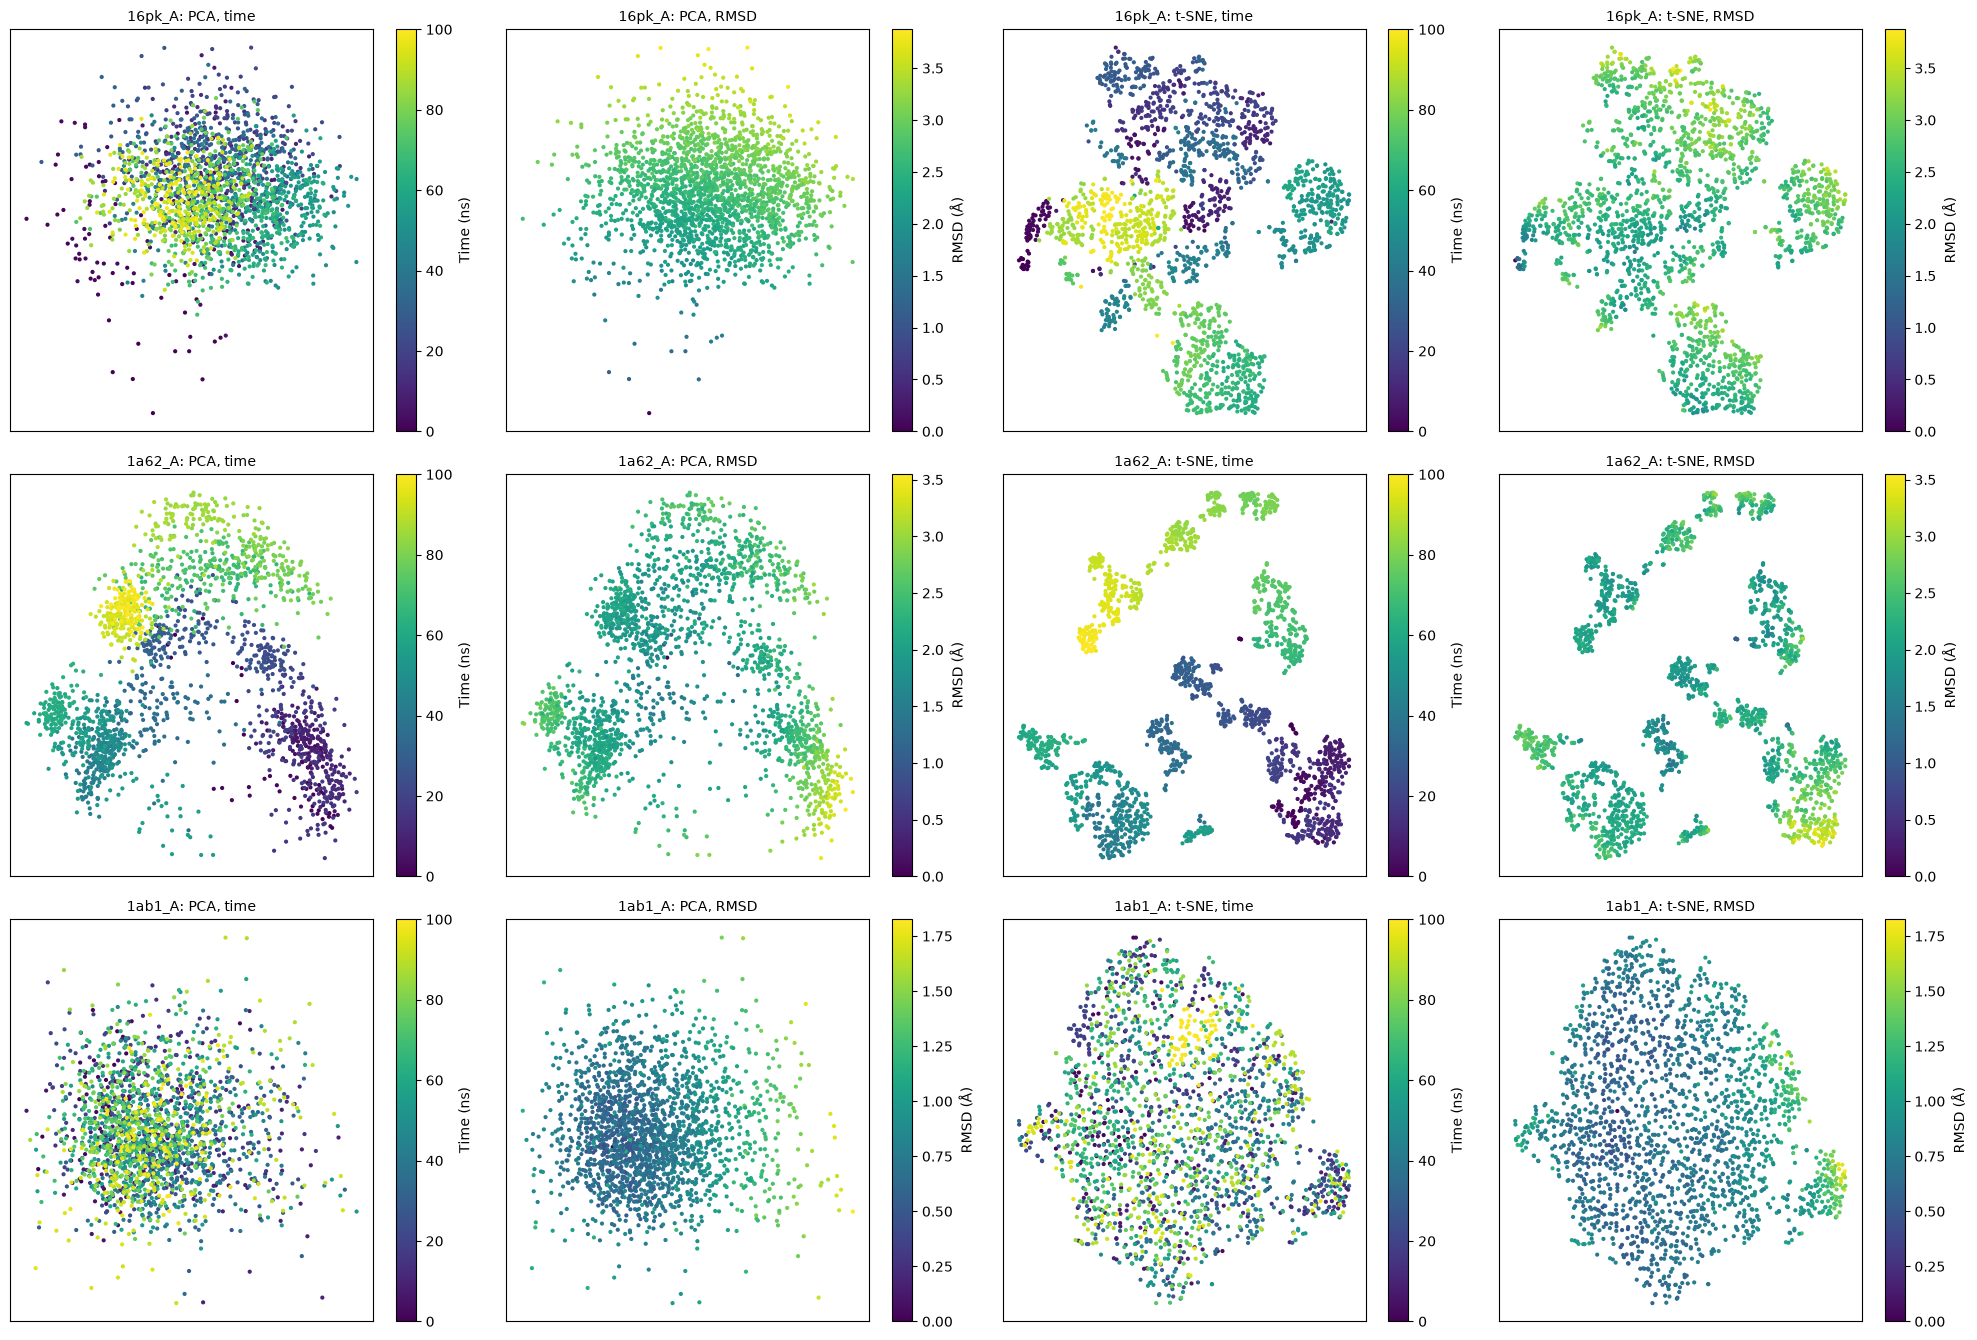

In [6]:
def plot_projection(ax, Y, colour, title, colour_label, connect=False):
    """Scatter a 2D projection. With connect=True, consecutive frames are joined by a thin line."""
    if connect:
        ax.plot(Y[:, 0], Y[:, 1], lw=0.3, c="gray", alpha=0.6, zorder=1)
    sc = ax.scatter(Y[:, 0], Y[:, 1], c=colour, s=4, zorder=2)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(sc, ax=ax, label=colour_label)


# Rows: proteins. Columns: PCA/t-SNE, coloured by time/RMSD.
fig, axes = plt.subplots(len(proteins), 4, figsize=(20, 4.5 * len(proteins)))
for row, protein in zip(axes, proteins):
    d = data[protein]
    plot_projection(row[0], d["coord_pca"],  d["time_ns"], f"{protein}: PCA, time",   "Time (ns)")
    plot_projection(row[1], d["coord_pca"],  d["rmsd"],    f"{protein}: PCA, RMSD",   "RMSD (Å)")
    plot_projection(row[2], d["coord_tsne"], d["time_ns"], f"{protein}: t-SNE, time", "Time (ns)")
    plot_projection(row[3], d["coord_tsne"], d["rmsd"],    f"{protein}: t-SNE, RMSD", "RMSD (Å)")
plt.tight_layout()
plt.show()

- 16pk_A: with the full 100 ns, the PCA is mostly one blob. In your first version, the early frames formed a separate group, but that was mainly the initial relaxation; over the whole simulation it hardly stands out. The t-SNE splits into clusters that each belong to one time period, which is the typical t-SNE effect of grouping consecutive frames, so these clusters aren't necessarily distinct conformations.
- 1a62_A: the PCA forms an arc, with time running along it from right (early) to left and then up (late). Be careful with this shape. PCA of a system that slowly drifts, like a random walk, naturally produces arcs or horseshoe shapes even without real states. The t-SNE again breaks the trajectory into many small, time-ordered clusters.
- 1ab1_A: no structure in any plot, with time colours fully mixed. Only the t-SNE coloured by RMSD shows a small group at the right edge with higher RMSD, which are likely the brief spikes from the RMSD plot.

## 4. Contact maps (graph of a single frame)

Every CA atom is a node; two nodes are connected if their distance is below a threshold.
The adjacency matrix of this graph is the **contact map**.

`pdist` computes all pairwise distances at once. It returns only the upper triangle (each pair once),
and `squareform` turns that into the full N × N matrix.

**Threshold:** consecutive CA atoms along the chain are always about 3.8 Å apart. With a 4.5 Å threshold,
almost only these chain neighbours are connected (the diagonal), and real contacts between different parts of the protein are missed.
Below we compare three thresholds; compare them with the contact map on the ATLAS website.

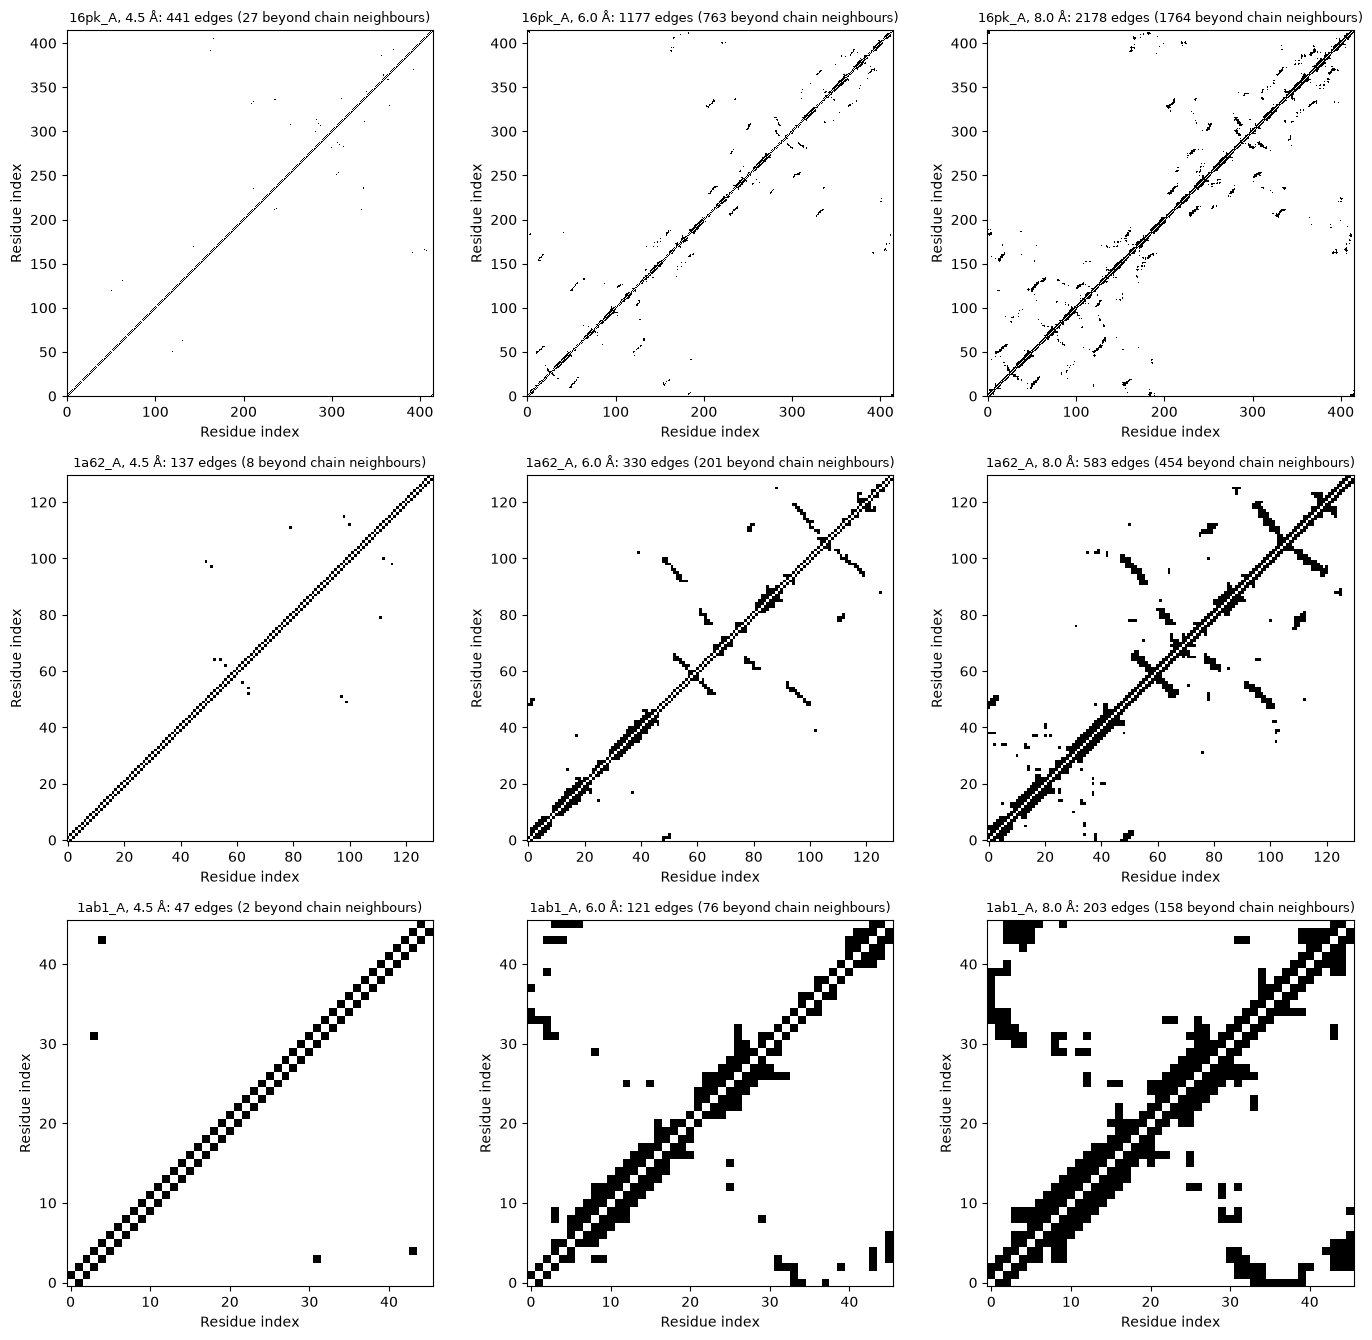

In [7]:
def contact_map(frame_coords, threshold):
    """Binary N x N contact map for one frame (coordinates in Å)."""
    distances = squareform(pdist(frame_coords))      # N x N distance matrix in Å
    adjacency = (distances < threshold).astype(int)
    np.fill_diagonal(adjacency, 0)                   # no self-loops
    return adjacency


fig, axes = plt.subplots(len(proteins), len(THRESHOLDS_TO_COMPARE), figsize=(14, 4.5 * len(proteins)))
for row, protein in zip(axes, proteins):
    N = data[protein]["coords"].shape[1]
    for ax, thr in zip(row, THRESHOLDS_TO_COMPARE):
        A = contact_map(data[protein]["coords"][0], thr)
        n_edges = A.sum() // 2
        n_chain = N - 1                               # edges between consecutive residues
        ax.imshow(A, origin="lower", cmap="Greys", interpolation="nearest")
        ax.set_title(f"{protein}, {thr} Å: {n_edges} edges ({n_edges - n_chain} beyond chain neighbours)", fontsize=9)
        ax.set_xlabel("Residue index"); ax.set_ylabel("Residue index")
plt.tight_layout()
plt.show()

### Contact map over time

The same protein at five moments in the simulation, using the chosen threshold.
Changes between these maps are what the network analysis below picks up.

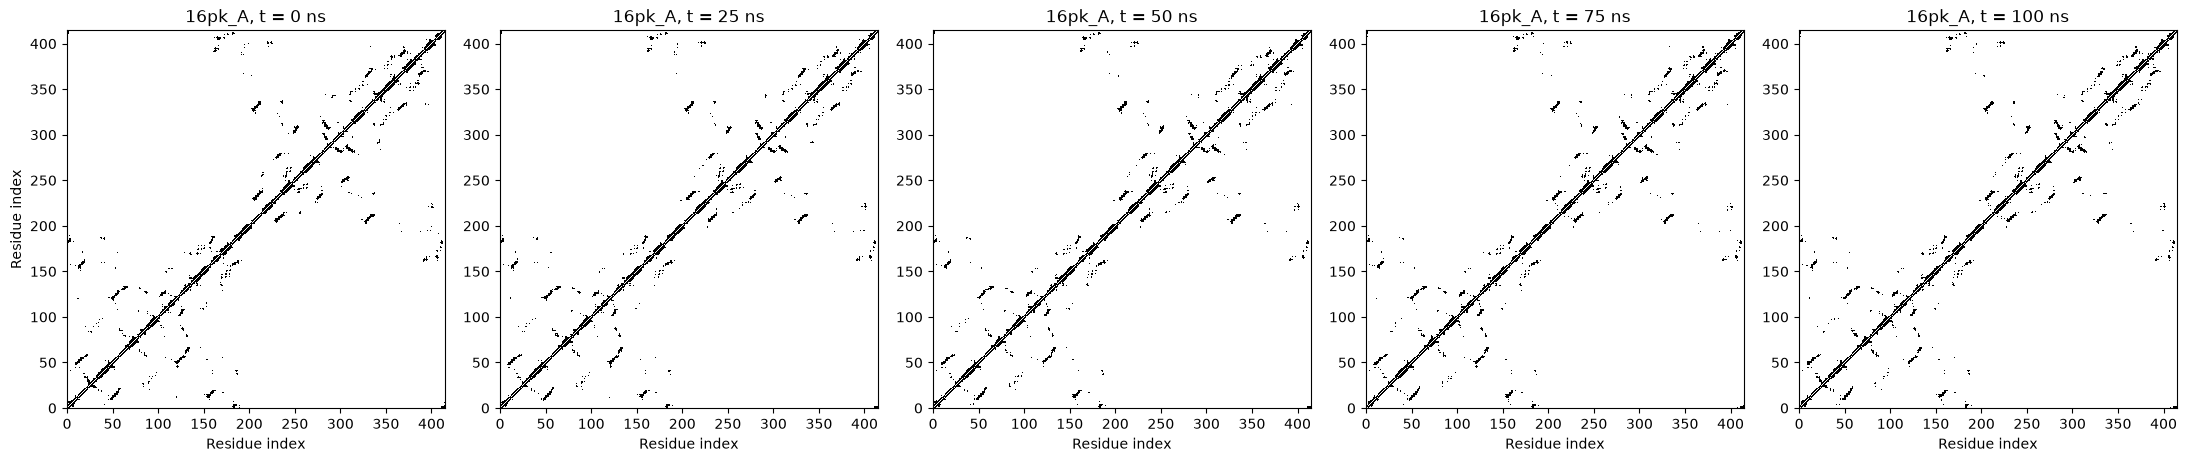

In [8]:
protein = "16pk_A"
coords = data[protein]["coords"]
time_ns = data[protein]["time_ns"]
frame_indices = np.linspace(0, len(coords) - 1, 5).astype(int)   # 5 evenly spaced frames

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, f in zip(axes, frame_indices):
    ax.imshow(contact_map(coords[f], CONTACT_THRESHOLD), origin="lower", cmap="Greys", interpolation="nearest")
    ax.set_title(f"{protein}, t = {time_ns[f]:.0f} ns")
    ax.set_xlabel("Residue index")
axes[0].set_ylabel("Residue index")
plt.tight_layout()
plt.show()

At 8 Å the maps show real protein structure, which 4.5 Å could not:

Thick bands along the diagonal are helices, because residues i and i+3/i+4 sit close together in a helix.
Lines perpendicular to the diagonal are antiparallel β strands. 1a62_A shows these clearly, for example around residues 50–60 against 85–100.
Lines parallel to the diagonal but away from it are parallel β strands, visible in 16pk_A.

For 16pk_A, the contacts concentrate in two blocks, roughly residues 0–190 and 190–415, with few contacts between them. That's the signature of a protein with two domains. If I remember correctly that 16PK is a phosphoglycerate kinase, this fits, since that enzyme has two domains connected by a hinge.

The contact maps over time for 16pk_A look nearly identical. That's expected: the fold stays intact throughout the simulation, and the changes are small, spread over the 1,331 contacts that flicker on and off.

## 5. Dynamic network: Snapshots-to-Points

Following the Snapshots-to-Points idea, each frame's contact map becomes one feature vector:
the upper triangle of the adjacency matrix (N(N-1)/2 binary values, one per residue pair).
Then the same DR methods are applied as for the coordinates.

**Removing constant contacts:** most pairs are either always in contact (e.g. chain neighbours) or never
(residues on opposite sides of the protein). These columns are identical in every frame, so they carry no information
for DR. Dropping them makes the computation much lighter (16pk_A has 85,905 pairs).
The number of remaining *varying* contacts is printed; if it is very small, the projection will collapse onto a few points.

In [9]:
def contact_features(coords, threshold):
    """One row per frame: the upper triangle of the contact map as booleans."""
    # pdist returns exactly the upper triangle (each residue pair once), in a fixed order
    return np.array([pdist(frame) < threshold for frame in coords])


network = {}

for protein in proteins:
    F = contact_features(data[protein]["coords"], CONTACT_THRESHOLD)   # (M, N(N-1)/2), bool

    # Keep only contacts that change at least once during the simulation
    varying = F.any(axis=0) & ~F.all(axis=0)
    F_var = F[:, varying].astype(np.float32)

    network[protein] = {"features": F_var, "varying_mask": varying}
    print(f"{protein}: {F.shape[1]} residue pairs, {varying.sum()} contacts change over time")

16pk_A: 85905 residue pairs, 1331 contacts change over time
1a62_A: 8385 residue pairs, 439 contacts change over time
1ab1_A: 1035 residue pairs, 102 contacts change over time


In [10]:
for protein in proteins:
    F = network[protein]["features"]

    pca = PCA(n_components=2)
    network[protein]["pca"] = pca.fit_transform(F)
    network[protein]["pca_var"] = pca.explained_variance_ratio_

    # Euclidean distance on binary vectors = sqrt(number of contacts that differ).
    # Alternative worth trying: metric="jaccard" (on the boolean features).
    network[protein]["tsne"] = TSNE(
        n_components=2, perplexity=30, init="pca", random_state=RANDOM_STATE
    ).fit_transform(F)

    v = network[protein]["pca_var"]
    print(f"{protein}: network PCA explained variance PC1 {v[0]:.1%}, PC2 {v[1]:.1%}, total {v.sum():.1%}")

16pk_A: network PCA explained variance PC1 3.6%, PC2 3.1%, total 6.7%
1a62_A: network PCA explained variance PC1 10.9%, PC2 5.4%, total 16.3%
1ab1_A: network PCA explained variance PC1 8.2%, PC2 7.6%, total 15.8%


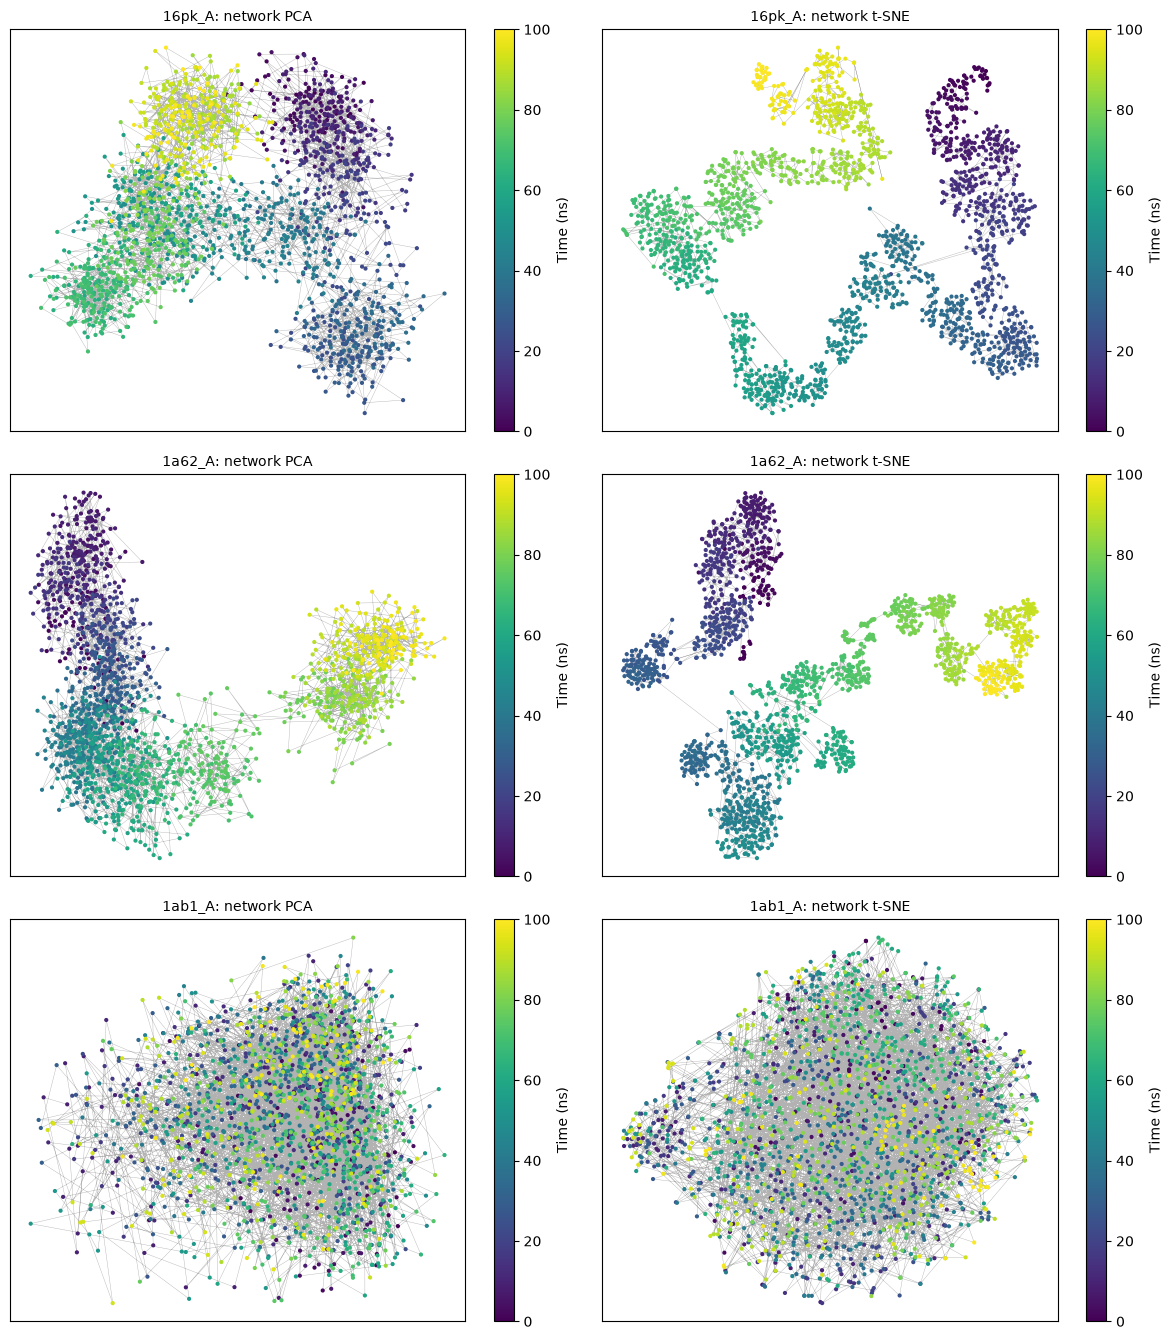

In [11]:
# Network projections, with consecutive frames connected (the trajectory through network space)
fig, axes = plt.subplots(len(proteins), 2, figsize=(12, 4.5 * len(proteins)))
for row, protein in zip(axes, proteins):
    t = data[protein]["time_ns"]
    plot_projection(row[0], network[protein]["pca"],  t, f"{protein}: network PCA",   "Time (ns)", connect=True)
    plot_projection(row[1], network[protein]["tsne"], t, f"{protein}: network t-SNE", "Time (ns)", connect=True)
plt.tight_layout()
plt.show()

16pk_A: this is the most striking result. The coordinate PCA was a blob, but the network PCA and t-SNE show a continuous path through time: the protein moves steadily from one region to the next and doesn't return to where it started. That suggests a slow, gradual rearrangement of its contacts over the 100 ns. The coordinate projection likely hides this because large, fast fluctuations (for example floppy loops and chain ends) dominate the coordinate variance.

1a62_A: the network PCA separates into two main regions, roughly 0–60 ns and 70–100 ns, with only a few frames in between. This could be a transition into a different contact state around 60–70 ns. It's the most interesting candidate for a closer look (see below).

1ab1_A: a noise ball, with no time structure. That matches its flat RMSD: the protein fluctuates around one state without changing its contacts in any organised way. Good as a negative control.

## 6. Coordinates vs. network

Side by side for each protein: the coordinate-based projection (step 3) and the network-based projection (step 5), both coloured by time.

Contact maps only depend on distances *within* the protein, so they ignore rotation and translation of the whole molecule.
Differences between the two columns therefore show what changes in the protein's *internal* structure,
as opposed to its overall position and shape in space.

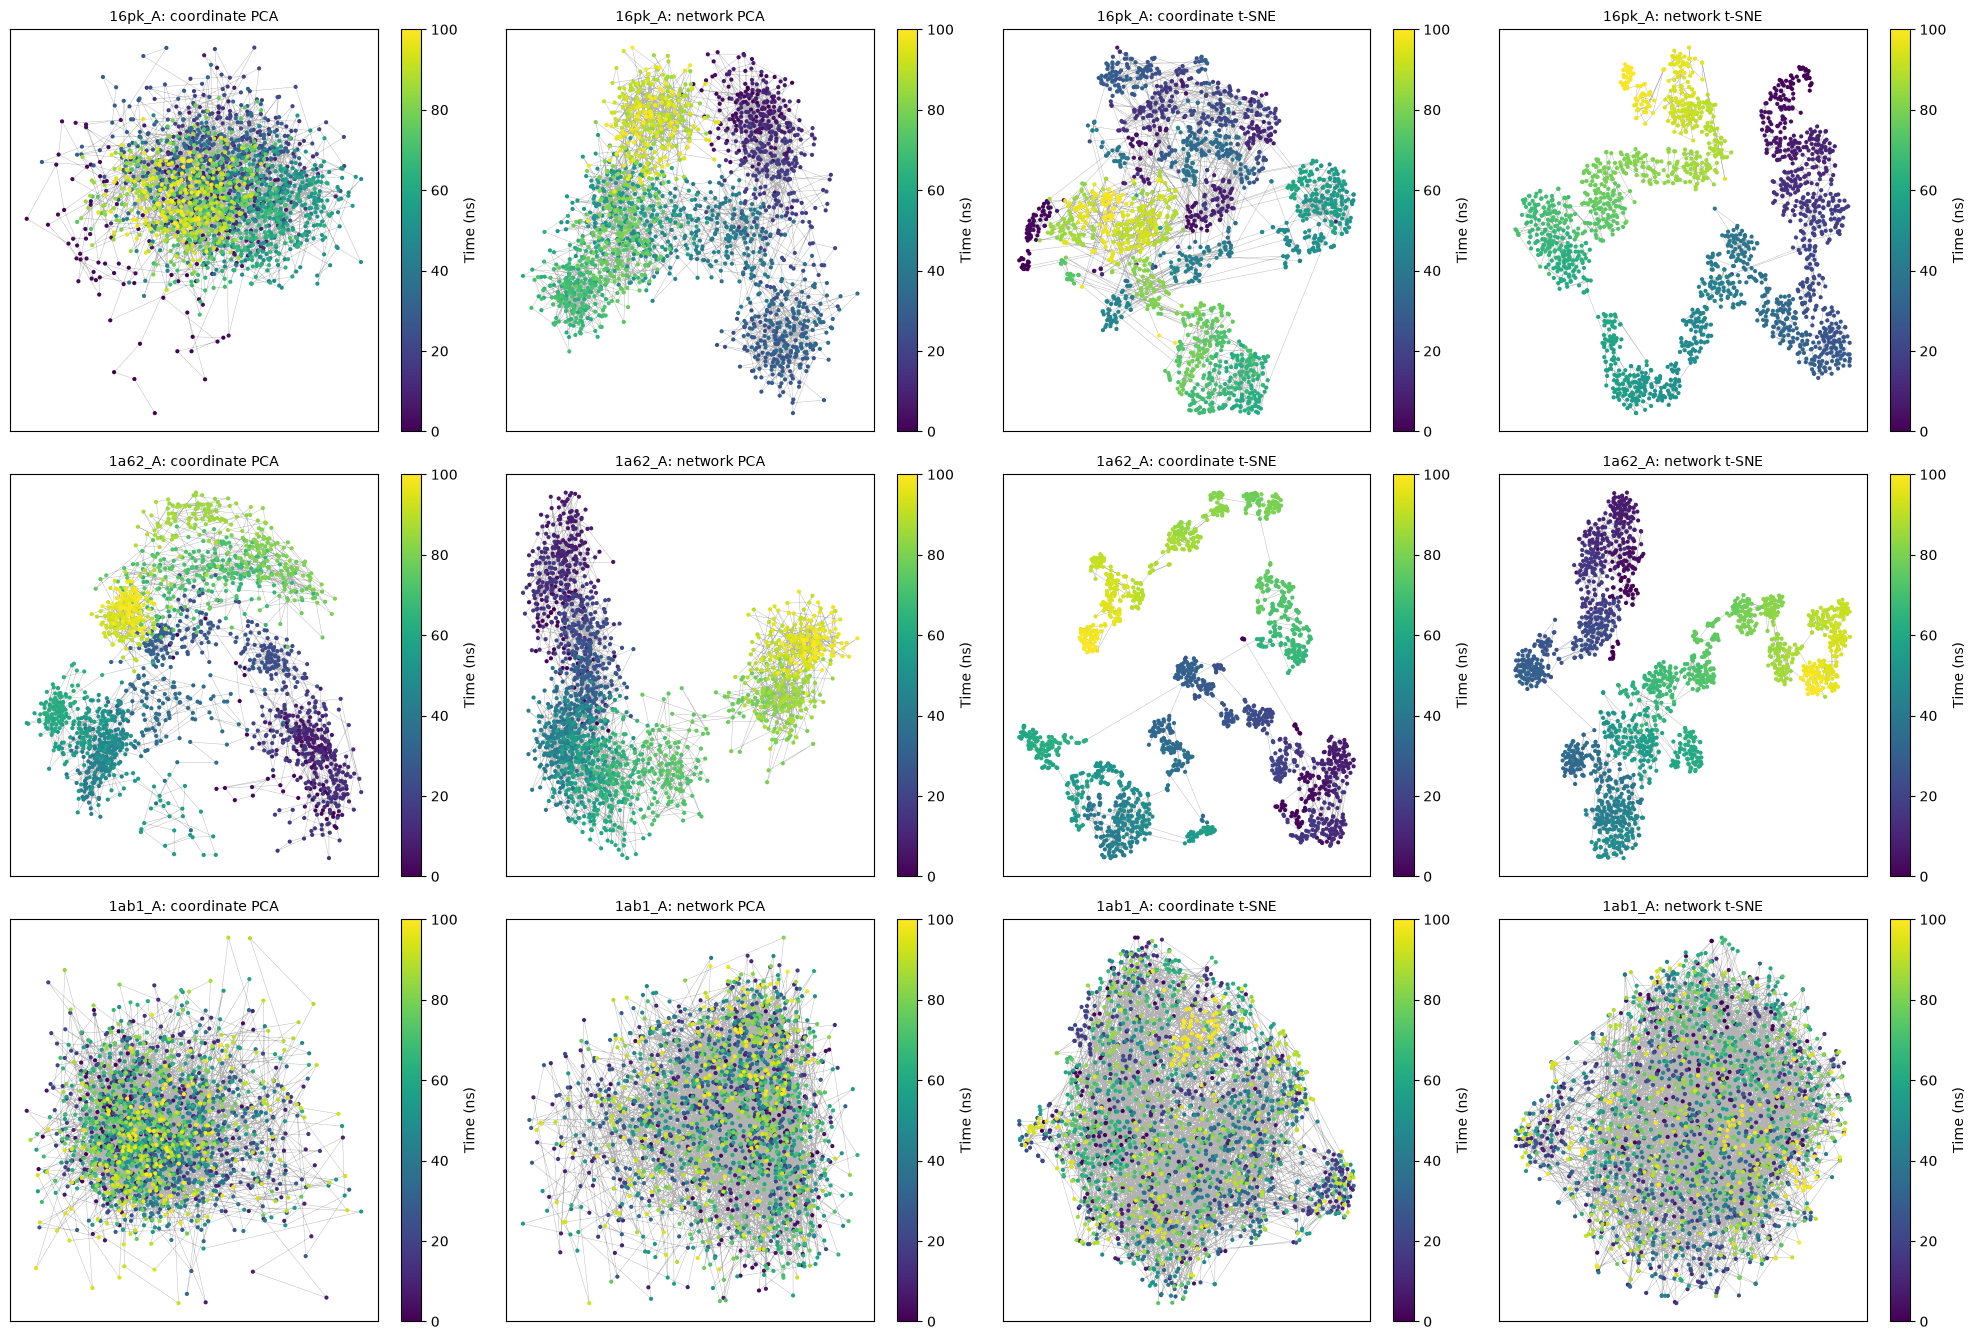

protein  residues  max RMSD (Å)  coord PCA 2D  varying contacts  network PCA 2D
16pk_A        415          3.87         48.9%              1331            6.7%
1a62_A        130          3.55         60.1%               439           16.3%
1ab1_A         46          1.83         43.6%               102           15.8%


In [12]:
fig, axes = plt.subplots(len(proteins), 4, figsize=(20, 4.5 * len(proteins)))
for row, protein in zip(axes, proteins):
    t = data[protein]["time_ns"]
    plot_projection(row[0], data[protein]["coord_pca"],  t, f"{protein}: coordinate PCA",  "Time (ns)", connect=True)
    plot_projection(row[1], network[protein]["pca"],     t, f"{protein}: network PCA",     "Time (ns)", connect=True)
    plot_projection(row[2], data[protein]["coord_tsne"], t, f"{protein}: coordinate t-SNE", "Time (ns)", connect=True)
    plot_projection(row[3], network[protein]["tsne"],    t, f"{protein}: network t-SNE",   "Time (ns)", connect=True)
plt.tight_layout()
plt.show()

# Summary table
print(f"{'protein':<8} {'residues':>8} {'max RMSD (Å)':>13} {'coord PCA 2D':>13} {'varying contacts':>17} {'network PCA 2D':>15}")
for protein in proteins:
    print(f"{protein:<8} {data[protein]['coords'].shape[1]:>8} {data[protein]['rmsd'].max():>13.2f} "
          f"{data[protein]['coord_pca_var'].sum():>13.1%} {network[protein]['varying_mask'].sum():>17} "
          f"{network[protein]['pca_var'].sum():>15.1%}")

The network PCA explains only 6.7% of the variance for 16pk_A, against 48.9% for coordinates, yet its plot shows much clearer structure. This is a good illustration that explained variance doesn't measure how useful a projection is. Many contacts flicker independently near the 8 Å cutoff and add a lot of unstructured variance. The slow, collective change is only a small part of the total variance, but it's the part that matters. This is a nice point to mention to your supervisor.

In [13]:
# Save results so the slow steps (t-SNE, contact features) don't need to be rerun
for protein in proteins:
    np.savez(
        f"{protein}_analysis.npz",
        time_ns=data[protein]["time_ns"],
        rmsd=data[protein]["rmsd"],
        coord_pca=data[protein]["coord_pca"],
        coord_tsne=data[protein]["coord_tsne"],
        network_pca=network[protein]["pca"],
        network_tsne=network[protein]["tsne"],
        contact_threshold=CONTACT_THRESHOLD,
    )

1a62_A is: which contacts differ between the two regions?

Text(0.5, 1.0, '1a62_A: early vs late')

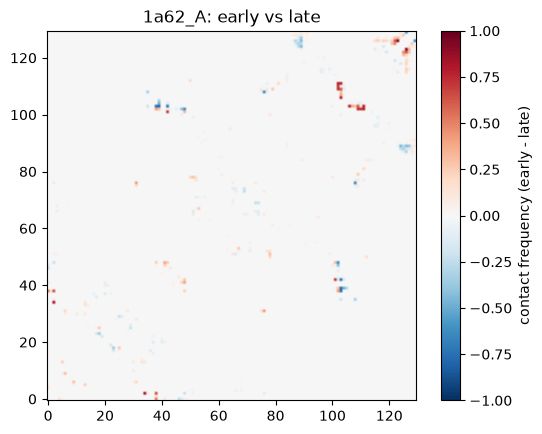

In [14]:
p = "1a62_A"
t, F, mask = data[p]["time_ns"], network[p]["features"], network[p]["varying_mask"]
diff = F[t < 60].mean(0) - F[t > 70].mean(0)          # contact frequency: early minus late
full = np.zeros(mask.size); full[mask] = diff         # put back into all residue pairs
plt.imshow(squareform(full), cmap="RdBu_r", vmin=-1, vmax=1, origin="lower")
plt.colorbar(label="contact frequency (early - late)"); plt.title(f"{p}: early vs late")

residues 123-126: +0.91
residues 2-34: +0.84
residues 39-103: -0.78
residues 103-106: +0.77
residues 102-111: +0.77
residues 103-111: +0.76
residues 38-103: -0.75
residues 102-109: +0.72


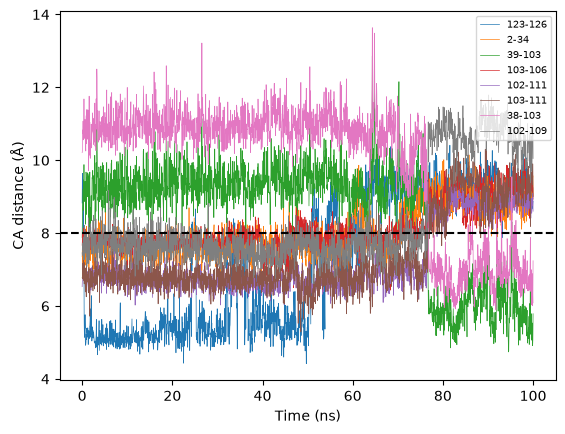

In [15]:
N = data[p]["coords"].shape[1]
I, J = np.triu_indices(N, k=1)                       # same pair order as pdist
top = np.argsort(-np.abs(full))[:8]                  # 8 most changed contacts
pairs = np.column_stack((I[top], J[top]))
for (i, j), v in zip(pairs, full[top]): print(f"residues {i}-{j}: {v:+.2f}")
d = md.compute_distances(data[p]["traj"], pairs) * 10   # CA distances over time, Å
for k, (i, j) in enumerate(pairs): plt.plot(t, d[:, k], lw=0.5, label=f"{i}-{j}")
plt.axhline(CONTACT_THRESHOLD, ls="--", c="k"); plt.legend(fontsize=7)
plt.xlabel("Time (ns)"); plt.ylabel("CA distance (Å)"); plt.show()

In [21]:
def windowed(F, width, step):
    starts = np.arange(0, len(F) - width + 1, step)
    W = np.array([F[s:s + width].mean(axis=0) for s in starts])   # contact frequency per window
    return W, starts + width // 2                                   # features, centre frame of each window

p = "1a62_A"
W, centres = windowed(network[p]["features"], width=20, step=4)    # overlap 0.8
tW = data[p]["time_ns"][centres]

In [22]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
variants = {
    "none": W,
    "binarized": (W > 0).astype(float),            # the paper's definition: present at all in the window
    "min-max": MinMaxScaler().fit_transform(W),
    "z-score": StandardScaler().fit_transform(W),
}

Text(0, 0.5, 'PC1')

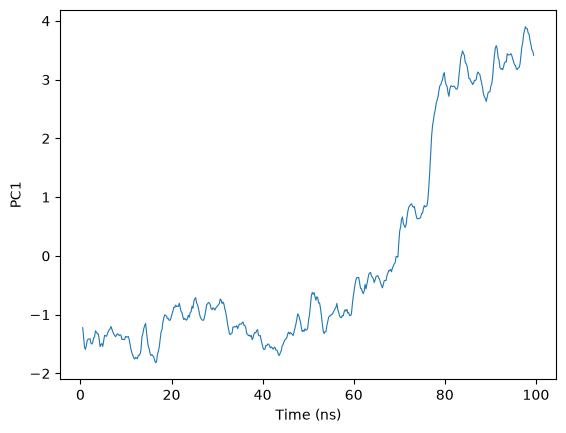

In [23]:
Y = PCA(n_components=2).fit_transform(W)
plt.plot(tW, Y[:, 0], lw=0.8)
plt.xlabel("Time (ns)"); plt.ylabel("PC1")